# Pronóstico de la demanda eléctrica del Perú

**Objetivo:** predecir la demanda eléctrica promedio de **mañana** en el SEIN
(Sistema Eléctrico Interconectado Nacional) usando la demanda de los días anteriores.

**Datos:** el [COES](https://www.coes.org.pe/Portal/portalinformacion/demanda) publica la demanda
del sistema cada 30 minutos (potencia promedio de ese intervalo, en MW).

Este notebook es el punto de partida típico de un proyecto de ML: todo en un solo lugar,
corrido a mano, de arriba a abajo.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import pandas as pd
import requests
import xgboost as xgb

## 1. Descargar los datos del COES

El portal acepta un rango de fechas (máximo un año por consulta) y devuelve un JSON con
tres series: la demanda **ejecutada** (lo que realmente pasó) y dos pronósticos oficiales del COES.

In [2]:
URL_COES = "https://www.coes.org.pe/Portal/portalinformacion/demanda"


def descargar_anio(anio):
    respuesta = requests.post(URL_COES, data={
        "fechaInicial": f"01/01/{anio}",
        "fechaFinal": f"31/12/{anio}",
    })
    series = {s["Name"]: s["Data"] for s in respuesta.json()["Chart"]["Series"]}
    demanda = pd.Series({r["Nombre"]: r["Valor"] for r in series["Ejecutado"]})
    pronostico = pd.Series({r["Nombre"]: r["Valor"] for r in series["Programación Diaria"]})
    df = pd.DataFrame({"demanda": demanda, "pronostico_coes": pronostico})
    return df.rename_axis("ts").reset_index()


df30 = pd.concat([descargar_anio(anio) for anio in range(2016, date.today().year + 1)])
df30["ts"] = pd.to_datetime(df30["ts"])
df30

,ts,demanda,pronostico_coes
0,2016-01-01 00:30:00,5050.95792,5062.13714
1,2016-01-01 01:00:00,4972.28087,4902.85159
2,2016-01-01 01:30:00,4840.34394,4796.95106
3,2016-01-01 02:00:00,4725.15682,4743.70501
4,2016-01-01 02:30:00,4585.50431,4689.13012
...,...,...,...
15547,2026-11-20 22:00:00,NaN,8224.11703
15548,2026-11-20 22:30:00,NaN,8048.64355
15549,2026-11-20 23:00:00,NaN,7847.93372
15550,2026-11-20 23:30:00,NaN,7627.92413


## 2. De cada 30 minutos a un valor por día

Cada dato está marcado al **final** de su intervalo: el de las `00:30` cubre de 00:00 a 00:30,
y el de las `00:00` es el último intervalo **del día anterior**. Por eso restamos 30 minutos
antes de agrupar. Nos quedamos solo con días completos (48 intervalos).

In [3]:
df30["fecha"] = (df30["ts"] - pd.Timedelta(minutes=30)).dt.normalize()
agrupado = df30.groupby("fecha")
diario = agrupado[["demanda", "pronostico_coes"]].mean()
diario = diario[agrupado["demanda"].count() == 48]
diario

,demanda,pronostico_coes
fecha,,
2016-01-01,4524.028291,4661.744380
2016-01-02,4989.102691,5082.269135
2016-01-03,4997.111846,5206.356072
2016-01-04,5464.874743,5634.452665
2016-01-05,5577.080624,5683.775139
...,...,...
2026-11-15,7316.776366,7153.775425
2026-11-16,7835.155130,7731.365029
2026-11-17,7975.823431,8022.015986


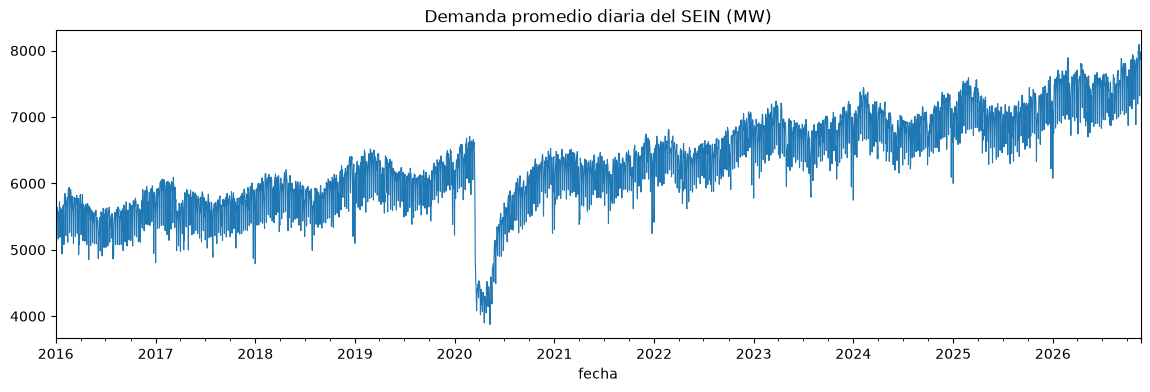

In [4]:
diario["demanda"].plot(figsize=(14, 4), title="Demanda promedio diaria del SEIN (MW)", lw=0.8)
plt.show()

Se ve el crecimiento año a año, la estacionalidad (más demanda en verano) y una caída
enorme en **marzo de 2020**: la cuarentena por COVID-19. Volveremos a ella al final.

## 3. Convertir la serie de tiempo en una tabla

XGBoost no sabe nada de tiempo: solo ve filas y columnas. Así que armamos una fila por día con
la demanda de los 14 días anteriores (*lags*) como features. El `lag_7` (mismo día de la semana
pasada) ya captura la estacionalidad semanal.

In [5]:
N_LAGS = 14

df = diario.copy()
for i in range(1, N_LAGS + 1):
    df[f"lag_{i}"] = df["demanda"].shift(i)
df["dia_semana"] = df.index.day_of_week
df = df.dropna()

FEATURES = [f"lag_{i}" for i in range(1, N_LAGS + 1)] + ["dia_semana"]
df[FEATURES + ["demanda"]].head()

,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,lag_13,lag_14,dia_semana,demanda
fecha,,,,,,,,,,,,,,,,
2016-01-15,5595.355350,5573.850495,5550.038116,5543.698299,5163.205452,5488.781951,5578.443132,5624.894372,5636.072622,5577.080624,5464.874743,4997.111846,4989.102691,4524.028291,4,5722.481594
2016-01-16,5722.481594,5595.355350,5573.850495,5550.038116,5543.698299,5163.205452,5488.781951,5578.443132,5624.894372,5636.072622,5577.080624,5464.874743,4997.111846,4989.102691,5,5517.845231
2016-01-17,5517.845231,5722.481594,5595.355350,5573.850495,5550.038116,5543.698299,5163.205452,5488.781951,5578.443132,5624.894372,5636.072622,5577.080624,5464.874743,4997.111846,6,5188.756991
2016-01-18,5188.756991,5517.845231,5722.481594,5595.355350,5573.850495,5550.038116,5543.698299,5163.205452,5488.781951,5578.443132,5624.894372,5636.072622,5577.080624,5464.874743,0,5629.005914
2016-01-19,5629.005914,5188.756991,5517.845231,5722.481594,5595.355350,5573.850495,5550.038116,5543.698299,5163.205452,5488.781951,5578.443132,5624.894372,5636.072622,5577.080624,1,5616.668119


## 4. Entrenar y evaluar

**Ojo:** en series de tiempo no se parte al azar (eso le mostraría el futuro al modelo).
Entrenamos con 2016-2018 y evaluamos con 2019, como si estuviéramos el 1 de enero de 2019.

Métrica: **MAPE** (error porcentual absoluto medio). Lo comparamos con el pronóstico oficial del COES.

In [6]:
train = df[df.index < "2019-01-01"]
test = df[(df.index >= "2019-01-01") & (df.index < "2020-01-01")]

modelo = xgb.XGBRegressor(n_estimators=400, max_depth=4, learning_rate=0.05)
modelo.fit(train[FEATURES], train["demanda"])
test = test.assign(prediccion=modelo.predict(test[FEATURES]))


def mape(real, prediccion):
    return ((real - prediccion).abs() / real).mean() * 100


print(f"MAPE de nuestro modelo en 2019:  {mape(test['demanda'], test['prediccion']):.2f}%")
print(f"MAPE del pronóstico COES en 2019: {mape(test['demanda'], test['pronostico_coes']):.2f}%")

MAPE de nuestro modelo en 2019:  2.06%
MAPE del pronóstico COES en 2019: 1.18%


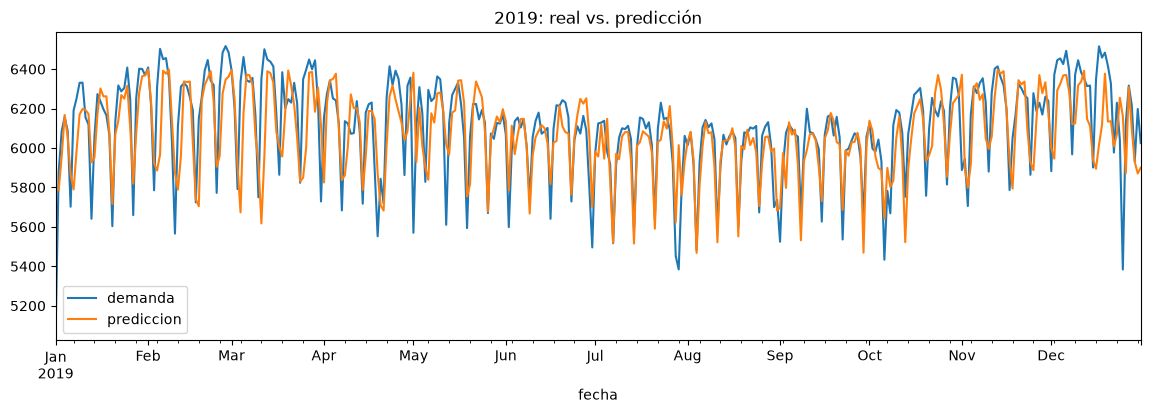

In [7]:
test[["demanda", "prediccion"]].plot(figsize=(14, 4), title="2019: real vs. predicción")
plt.show()

Un modelo muy simple con ~2% de error. ¡Listo para producción! ...¿o no?

## 5. Lo que pasa en la vida real

Supongamos que ponemos este modelo "en producción" el 1 de enero de 2020 y nos olvidamos de él.

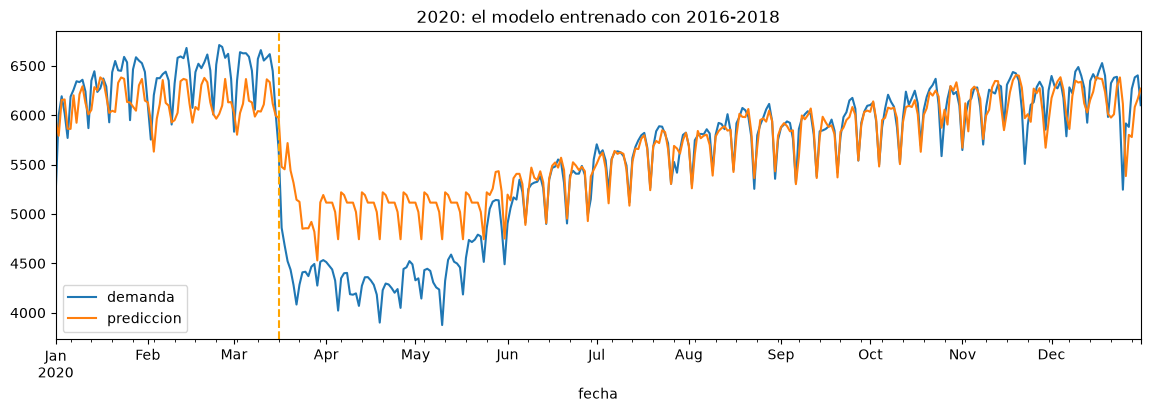

fecha
1      3.5
2      4.7
3     10.3
4     18.4
5     12.0
6      1.6
7      1.0
8      1.1
9      1.0
10     1.3
11     2.2
12     3.4
Name: MAPE por mes (%), dtype: float64

In [8]:
anio_2020 = df[(df.index >= "2020-01-01") & (df.index < "2021-01-01")]
anio_2020 = anio_2020.assign(prediccion=modelo.predict(anio_2020[FEATURES]))

anio_2020[["demanda", "prediccion"]].plot(figsize=(14, 4), title="2020: el modelo entrenado con 2016-2018")
plt.axvline(pd.Timestamp("2020-03-16"), color="orange", ls="--")
plt.show()

errores = (anio_2020["demanda"] - anio_2020["prediccion"]).abs() / anio_2020["demanda"] * 100
errores.groupby(anio_2020.index.month).mean().round(1).rename("MAPE por mes (%)")

El 16 de marzo de 2020 empieza la cuarentena y la demanda cae ~38%. El modelo se equivoca
hasta 20% durante semanas... **y nadie se entera**, porque el modelo vive en un notebook.

## Lo que le falta a este notebook (y el plan del proyecto)

| Problema | Solución | Tag |
|---|---|---|
| Todo mezclado, difícil de reusar y de revisar | Separar en scripts: ingesta, features, entrenamiento, predicción. Registrar experimentos | `v1-modular` |
| "En mi máquina funciona" | Tests automáticos que corren en un contenedor en cada push (CI) | `v2-tests-ci` |
| Alguien tiene que correrlo a mano | Un job diario en la nube que trae los datos nuevos y predice solo | `v3-nuevos-datos` |
| Nadie se entera cuando el modelo falla | Monitorear el error y reentrenar automáticamente | `v4-monitoreo` |